# Is Benchmark Contamination Heritable?
### A quantitative-genetics analysis of the Hugging Face LLM family tree

**Team:** Ullas T (PES1UG24AM309) Â· Sampreeth Jaladi (PES1UG24AM246) Â· Deepthi A E (PES1UG24AM358)
**Course:** Algorithms for Data Analytics (ADA), 2026 Â· **Repository:** https://github.com/minkysponge-wq/Ada-Mini-project

**Question.** Open-weight LLMs are built from each other (fine-tunes, merges), forming a family tree on the
Hugging Face Hub. Is benchmark contamination *inherited* along that tree, the way a trait is inherited in a pedigree?

**Approach.**
1. Rebuild the family tree from Hub `base_model` metadata.
2. Measure each model's **inflation**: its percentile rank on Open LLM Leaderboard **v1** (older benchmarks, widely
   leaked: ARC, HellaSwag, MMLU, TruthfulQA, Winogrande, GSM8K) minus its rank on **v2** (newer, harder: IFEval, BBH,
   MATH Lvl 5, GPQA, MuSR, MMLU-Pro).
3. Estimate the **heritability hÂ²** of inflation with the *animal model* (pedigree linear mixed model, REML).
4. Separate contamination from genuine capability (TA question), study how it is inherited (merges, generations),
   check robustness, and validate against a direct memorisation test (GSM-Symbolic / GSM-Plus).

This notebook runs every analysis from the cached dataset in `out_phase1/data` (no internet, no GPU needed) and shows
the results inline. Each step calls one script from the repository; the scripts hold the full implementation.

## 0. Setup
Works locally (from the repository folder) or on Google Colab (clones the repository first).

In [1]:
import os, sys, json, subprocess
if 'google.colab' in sys.modules and not os.path.exists('part2_analysis.py'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/minkysponge-wq/Ada-Mini-project.git', '/content/ada'])
    os.chdir('/content/ada')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'])

import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)

DATA, OUT = 'out_phase1/data', 'out_phase1'
def run(script, *args):
    r = subprocess.run([sys.executable, script, *args], capture_output=True, text=True)
    lines = [l for l in r.stdout.splitlines() if l.strip()]
    print('\n'.join(lines[-40:]))
    if r.returncode != 0:
        print(r.stderr[-3000:]); raise RuntimeError(script + ' failed')
def show(*paths, width=720):
    for p in paths: display(Image(filename=p, width=width))
print('working directory:', os.getcwd())

working directory: C:\College\ADA mini porj\ada_contam


## 1. Dataset and family tree (Part 1)
`part1_pedigree.py` downloads the v1 and v2 leaderboard scores and every model's Hub metadata (`base_model`,
relation tags), matches renamed repositories between the two leaderboards, and builds the pedigree.
It needs internet and a Hugging Face token and takes up to an hour because of Hub rate limits, so it is **not rerun
here**; its output is the cached dataset in `out_phase1/data`. To rebuild it:
`python part1_pedigree.py --out out_phase1` (with `HF_TOKEN` set).

In [2]:
RUN_PART1 = False          # set True to re-download everything (internet + HF_TOKEN, ~1 hour)
if RUN_PART1:
    run('part1_pedigree.py', '--out', OUT)
panel = pd.read_csv(f'{DATA}/panel.csv'); nodes = pd.read_csv(f'{DATA}/nodes.csv'); edges = pd.read_csv(f'{DATA}/edges.csv')
print(f'family tree: {len(nodes):,} models, {len(edges):,} parent links, max generation {int(nodes.generation.max())}')
print(f'analysis panel (scored on both v1 and v2, still on the Hub): {len(panel)} models, '
      f'{(panel.n_parents > 0).sum()} with a parent in the tree')
panel[['model_id', 'generation', 'founder', 'is_merge', 'v1_avg', 'v2_avg', 'v1_pct', 'v2_pct', 'inflation']].head(8)

family tree: 13,148 models, 11,541 parent links, max generation 151
analysis panel (scored on both v1 and v2, still on the Hub): 405 models, 98 with a parent in the tree


,model_id,generation,founder,is_merge,v1_avg,v2_avg,v1_pct,v2_pct,inflation
0,paloalma/Le_Triomphant-ECE-TW3,0,paloalma/Le_Triomphant-ECE-TW3,False,81.305471,31.996294,100.000000,97.037037,2.962963
1,jsfs11/MixtureofMerges-MoE-4x7b-v5,12,mlabonne/Marcoro14-7B-slerp,True,76.022838,20.434941,90.864198,66.419753,24.444444
2,mlabonne/AlphaMonarch-7B,11,mlabonne/Marcoro14-7B-slerp,False,75.988300,17.630621,90.617284,49.876543,40.740741
3,abacusai/Smaug-72B-v0.1,1,moreh/MoMo-72B-lora-1.8.7-DPO,False,80.481415,29.737299,99.012346,95.061728,3.950617
4,152334H/miqu-1-70b-sf,0,152334H/miqu-1-70b-sf,False,76.590279,29.097408,92.345679,94.074074,-1.728395
5,mlabonne/NeuralBeagle14-7B,3,mlabonne/Marcoro14-7B-slerp,False,74.741181,18.910076,84.938272,56.296296,28.641975
6,microsoft/Orca-2-13b,0,microsoft/Orca-2-13b,False,61.981357,18.501871,44.197531,55.061728,-10.864198
7,Intel/neural-chat-7b-v3-1,1,mistralai/Mistral-7B-v0.1,False,61.590097,21.067927,42.716049,71.358025,-28.641975


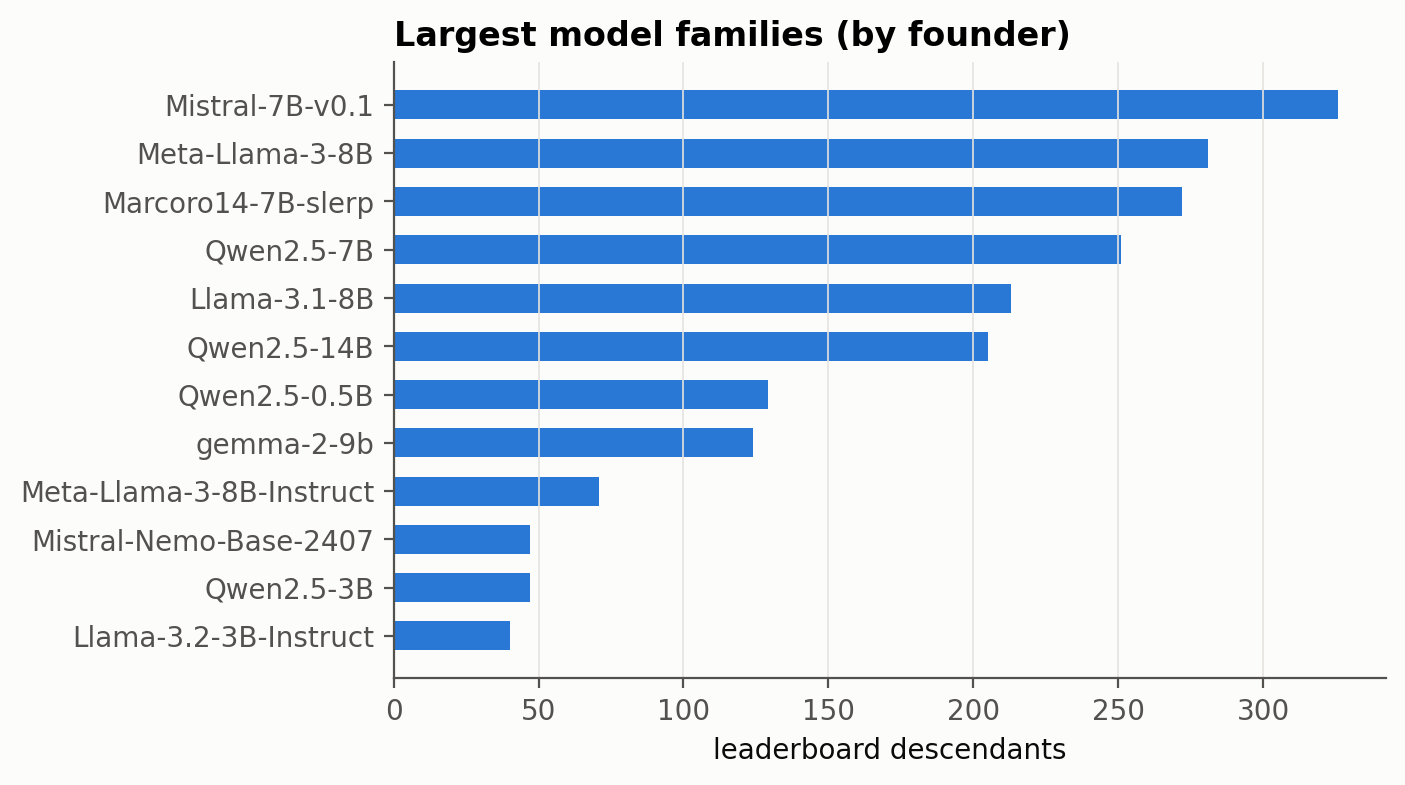

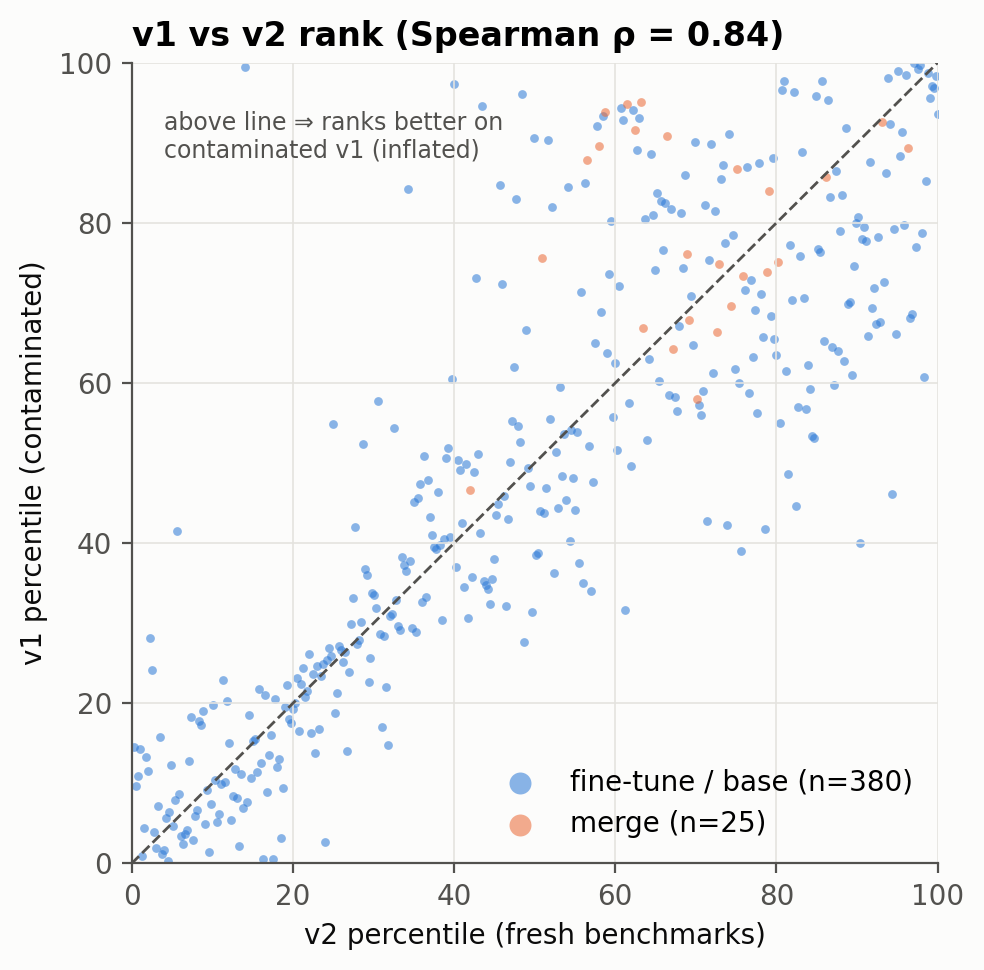

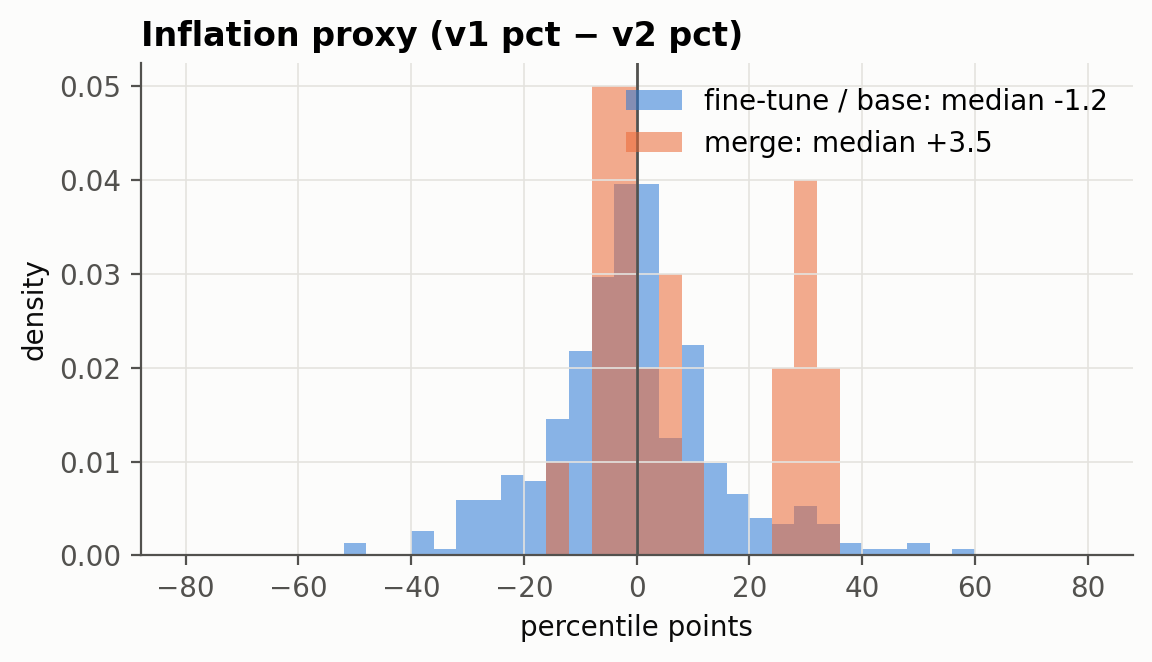

In [3]:
show(f'{OUT}/figs/04_families.png', f'{OUT}/figs/05_rank_scatter.png', f'{OUT}/figs/06_inflation_hist.png')

## 2. Is inflation heritable? (Part 2: animal model)
Inflation y is modelled as `y = XÎ² + a + e`, with `a ~ N(0, ÏƒÂ²_a A)` where **A** is the kinship matrix from the
pedigree and X holds non-lineage covariates (size, date, architecture, type, MoE). **hÂ² = ÏƒÂ²_a / (ÏƒÂ²_a + ÏƒÂ²_e)**,
estimated by exact REML on the eigendecomposition of A, with a profile-likelihood 95% CI, a likelihood-ratio test and
a permutation test. Two kinship models: *diploid* (merge = two parents, Â½ each) and *clonal* (fine-tune = copy;
conservative, our primary model). The script also covers inheritance mode (generation trend) and lineage-only
prediction (cross-validated BLUP, detector ROC).

In [4]:
run('part2_analysis.py', '--data', DATA, '--out', OUT)

   "n": 405
  }
 ],
 "permutation_p_inflation": 0.014925373134328358,
 "inheritance": {
  "midparent_finetune": {
   "n": 53,
   "slope": 0.2349806474170284,
   "slope_se": 0.17035495687019317,
   "intercept": -4.409095252381927,
   "r": 0.18964381538768776,
   "p": 0.1738028687793897
  },
  "generation": {
   "slope": 0.6609879392005418,
   "p": 0.02834417604899094,
   "mean_step_change": -3.32010582010582,
   "step_p": 0.09639698488410678
  }
 },
 "prediction": {
  "cv_r2": {
   "Covariates only (size, arch, date, type)": 0.17230611638960192,
   "Family mean (founder)": 0.08426134135843233,
   "Pedigree BLUP + covariates": 0.22684772062224856
  },
  "cv_spearman": {
   "Covariates only (size, arch, date, type)": 0.3499460937249344,
   "Family mean (founder)": 0.13445050632911265,
   "Pedigree BLUP + covariates": 0.4265851308286419
  },
  "detector_auc": {
   "Covariates only (size, arch, date, type)": 0.6614158497343411,
   "Family mean (founder)": 0.5776584599266632,
   "Pedigree BL

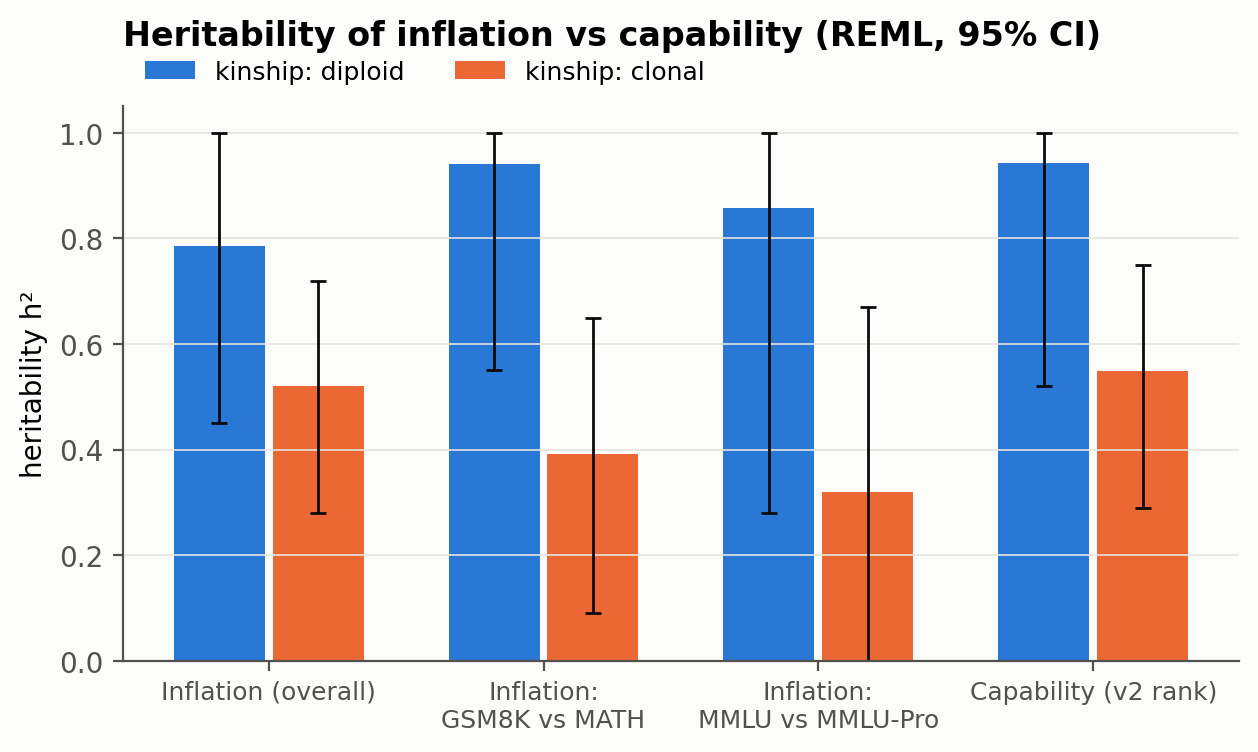

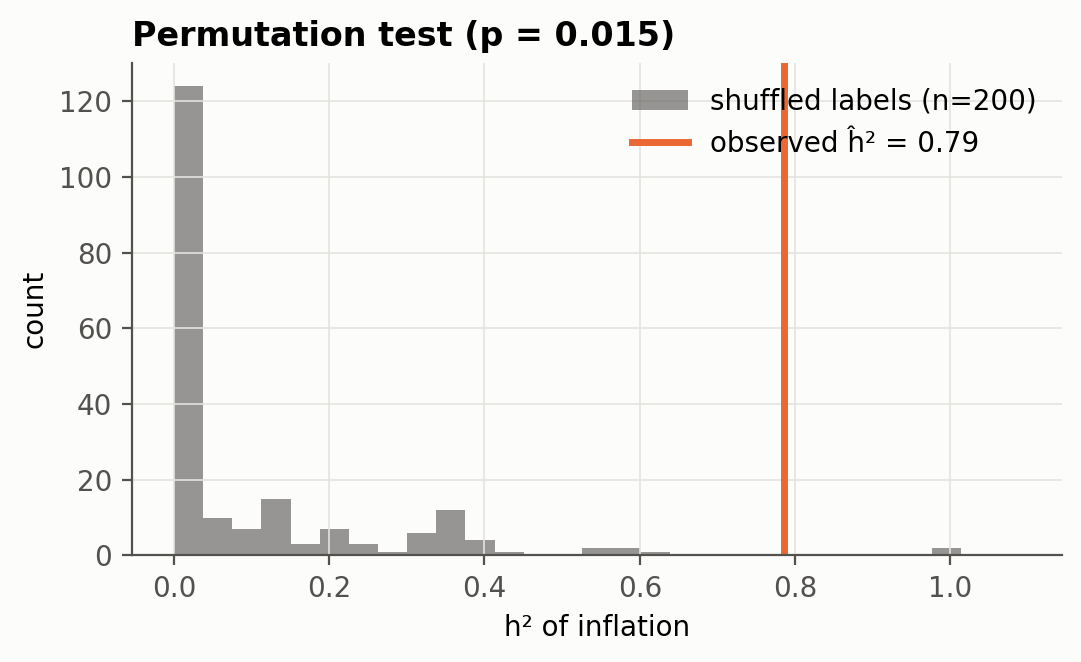

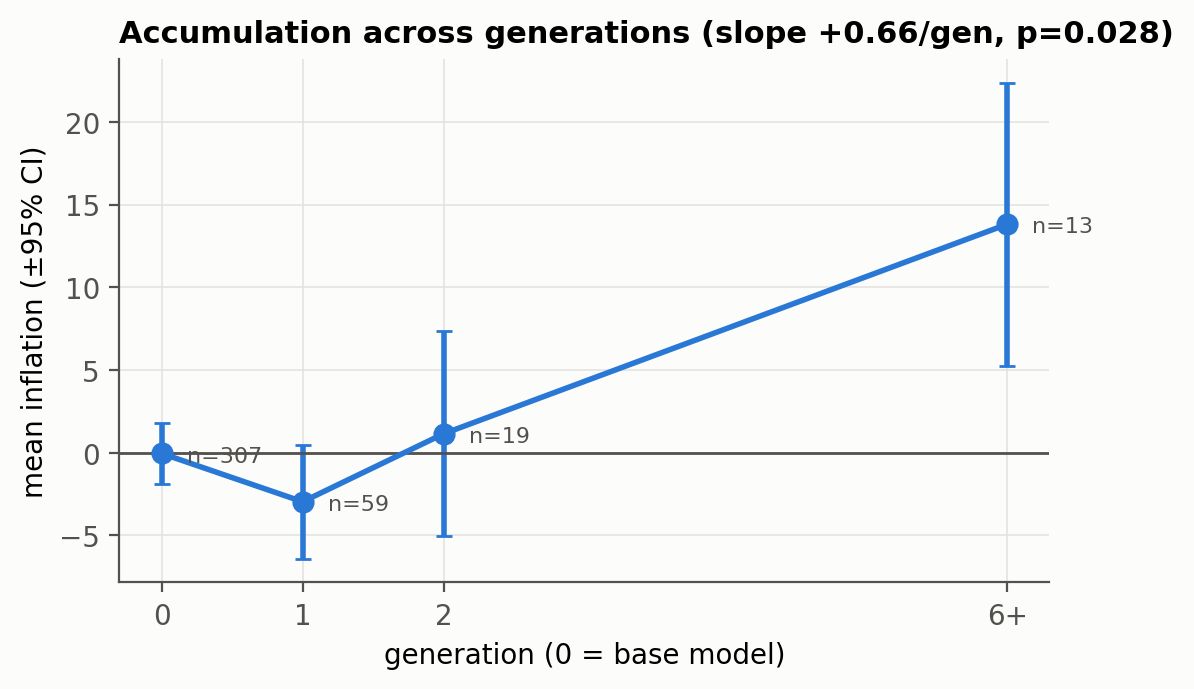

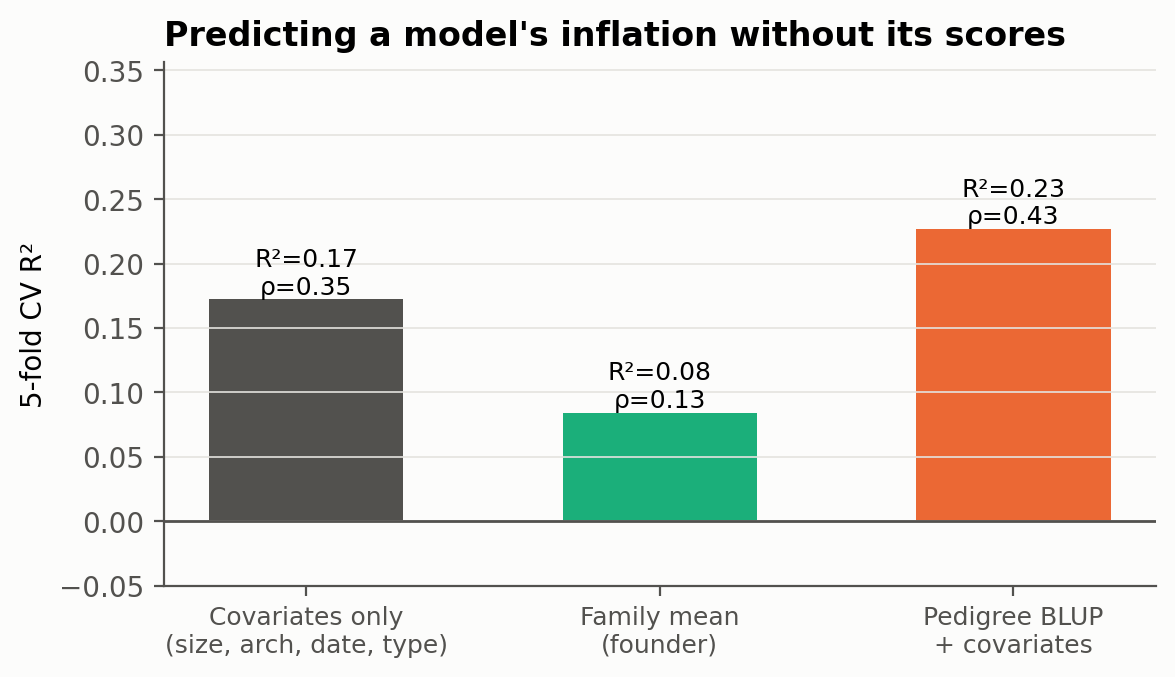

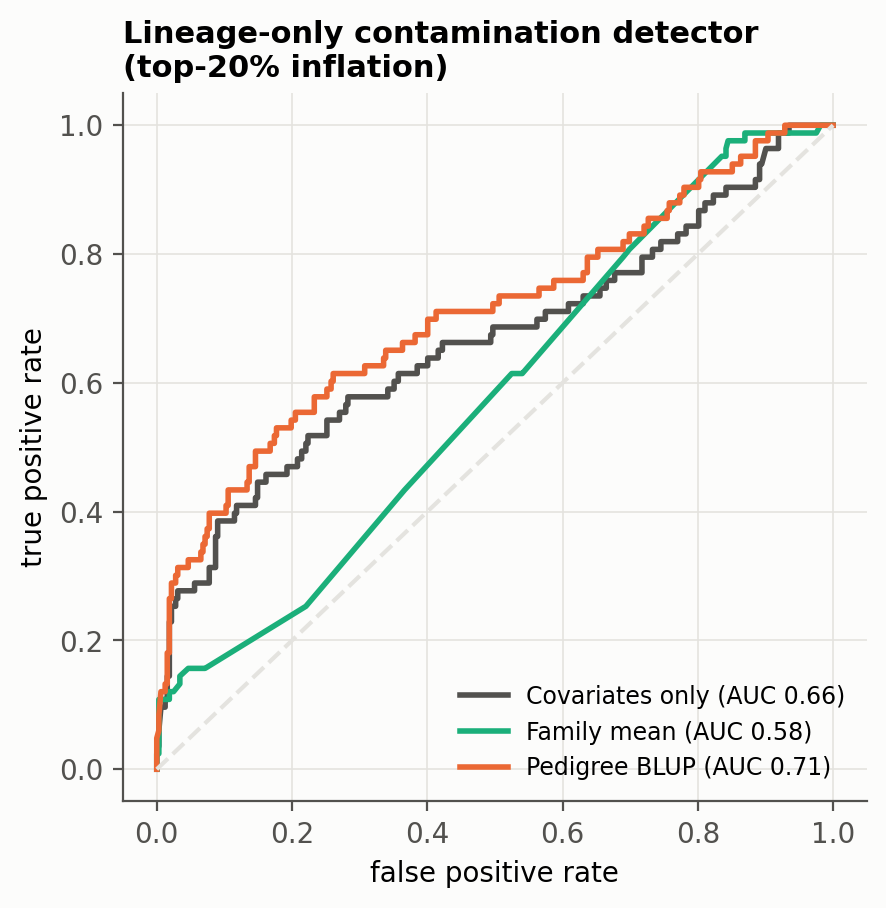

In [5]:
show(f'{OUT}/figs/08_h2_bars.png', f'{OUT}/figs/10_permutation_null.png', f'{OUT}/figs/13_generation_trend.png',
     f'{OUT}/figs/14_cv_prediction.png', f'{OUT}/figs/15_detector_roc.png')

## 3. Is the Hub lineage data good enough? (Phase 1 audit, TA question 2)
How many models have documented parents, where the links come from, and whether hÂ² holds on the well-documented subset.

  "no lineage (founder or undocumented)": 6943,
  "relation tags": 3814,
  "card base_model only": 112,
  "leaderboard column only": 43
 },
 "lineage_source_panel": {
  "no lineage (founder or undocumented)": 306,
  "relation tags": 99
 },
 "panel_with_any_parent": 99,
 "distinct_parents_referenced": 4214,
 "parents_hub_ok": 3845,
 "parents_hub_missing_or_gated": 368,
 "parents_not_fetched_depth_limit": 1,
 "relation_counts": {
  "merge": 8535,
  "finetune": 2679,
  "adapter": 192,
  "quantized": 135
 },
 "panel_families": 324,
 "panel_families_with_2plus": 27,
 "panel_models_in_2plus_families": 108,
 "panel_models_with_a_relative_in_panel": 127,
 "related_pairs_in_panel": 569
}
[h2 sensitivity]
  All panel models                       n= 405 clonal  inflation h2=0.52 [0.28,0.72] p=6.4e-07
  All panel models                       n= 405 clonal  v2_pct    h2=0.55 [0.29,0.75] p=7.8e-06
  All panel models                       n= 405 diploid inflation h2=0.79 [0.45,1.00] p=7.2e-06
  All p

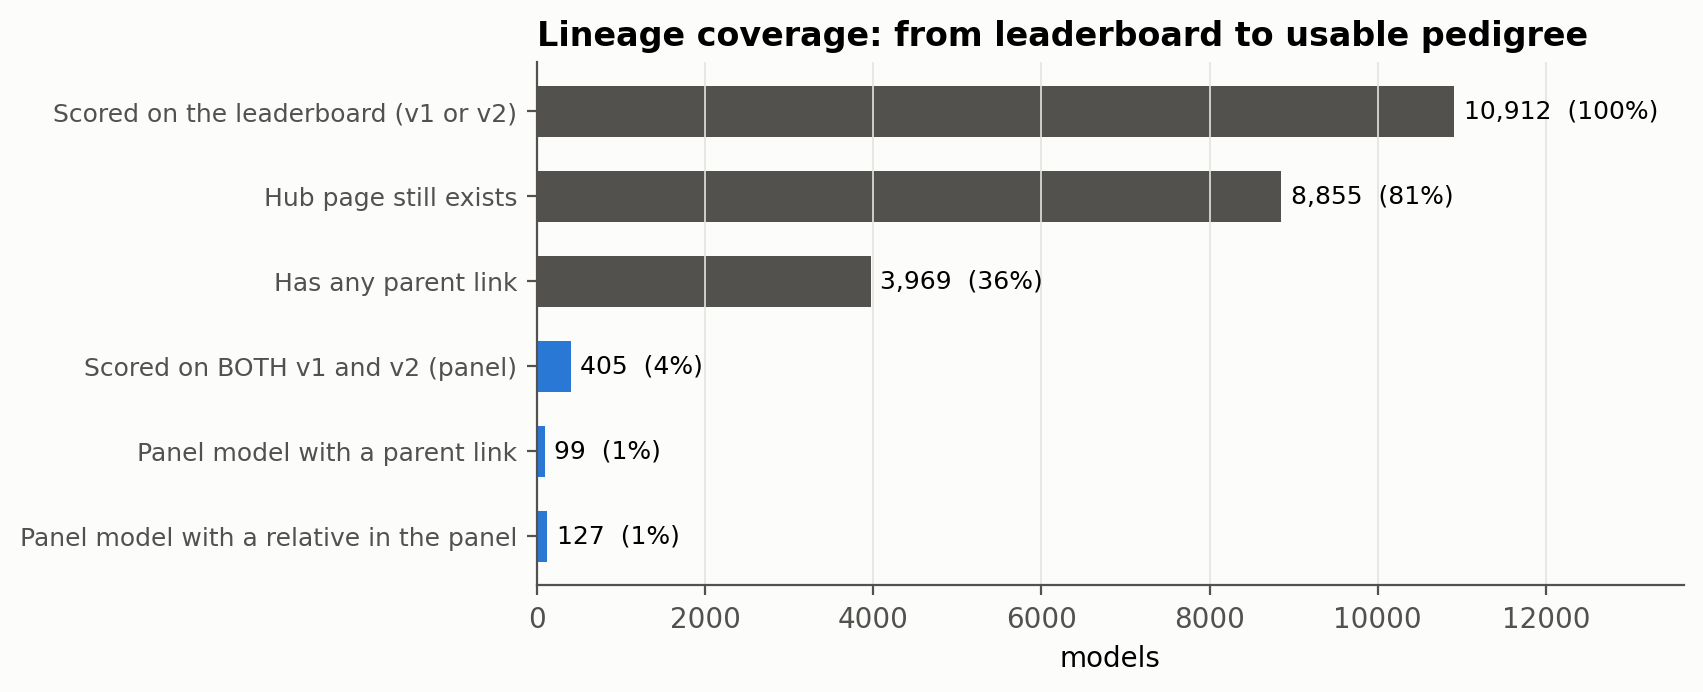

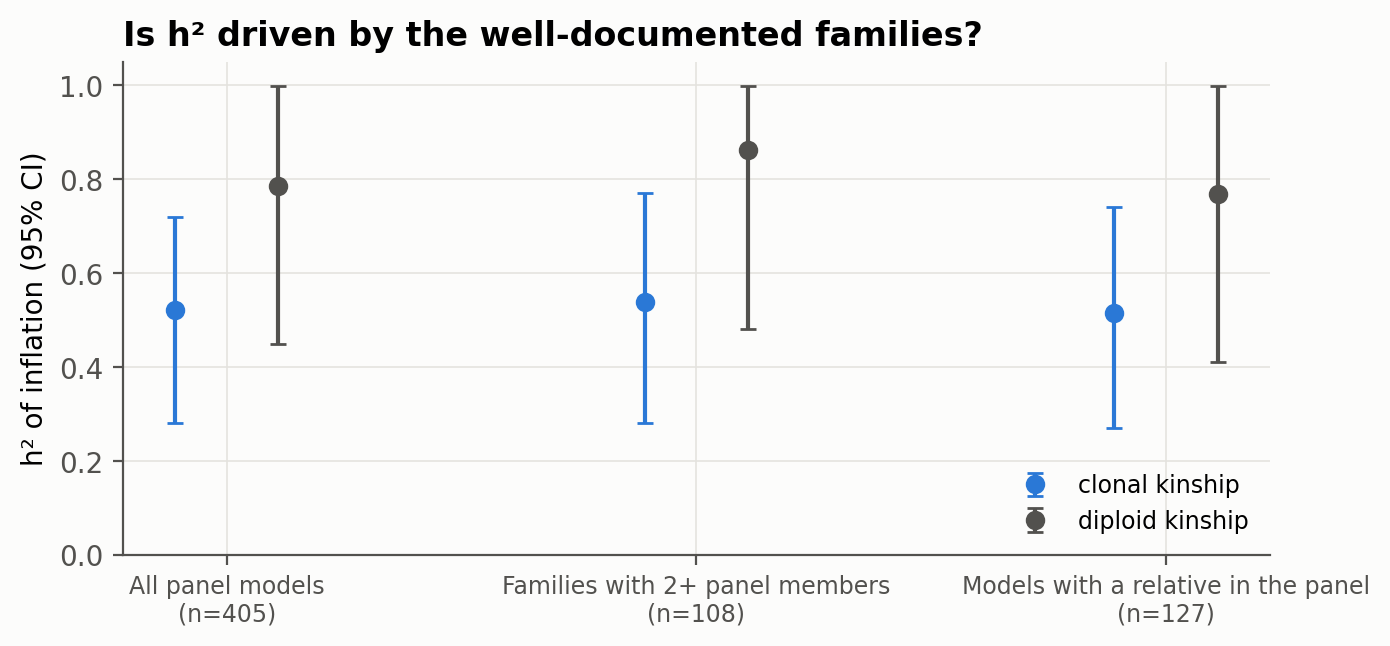

In [6]:
run('phase1_audit.py', '--data', DATA, '--out', OUT)
show(f'{OUT}/phase1/figs/P1_coverage_funnel.png', f'{OUT}/phase1/figs/P1_h2_sensitivity.png')

## 4. Separating contamination from capability (Phase 2, TA question 1)
Four tests: **A** residual proxy (v1 rank minus a cubic fit on v2 rank, uncorrelated with capability by construction);
**B** capability as a covariate; **C** genetic correlation r_g between inflation and capability (bivariate animal
model); **D** placebo: the same gap between pairs of *clean* v2 tasks. If contamination is what is inherited,
contaminated-vs-clean gaps should be more heritable than clean-vs-clean gaps, and r_g should be near 0.

[load] panel 405 models
[A] corr(raw gap, capability)=-0.294  corr(residual gap, capability)=0.017
[B] clonal  raw gap (Part 2 proxy)                        h2=0.52 [0.28,0.72] p=6.4e-07
[B] clonal  raw gap + capability covariate                h2=0.70 [0.50,0.83] p=1.5e-11
[B] clonal  residual gap                                  h2=0.62 [0.39,0.79] p=1.7e-08
[B] clonal  capability (v2 rank)                          h2=0.55 [0.29,0.75] p=7.8e-06
[B] clonal  residual gap: math (GSM8K vs MATH)            h2=0.44 [0.16,0.67] p=0.00097
[B] clonal  residual gap: knowledge (MMLU vs MMLU-Pro)    h2=0.33 [0.02,0.65] p=0.015
[B] diploid raw gap (Part 2 proxy)                        h2=0.79 [0.45,1.00] p=7.2e-06
[B] diploid raw gap + capability covariate                h2=0.88 [0.60,1.00] p=5.1e-08
[B] diploid residual gap                                  h2=0.82 [0.51,1.00] p=9.9e-07
[B] diploid capability (v2 rank)                          h2=0.94 [0.52,1.00] p=0.00011
[B] diploid residual ga

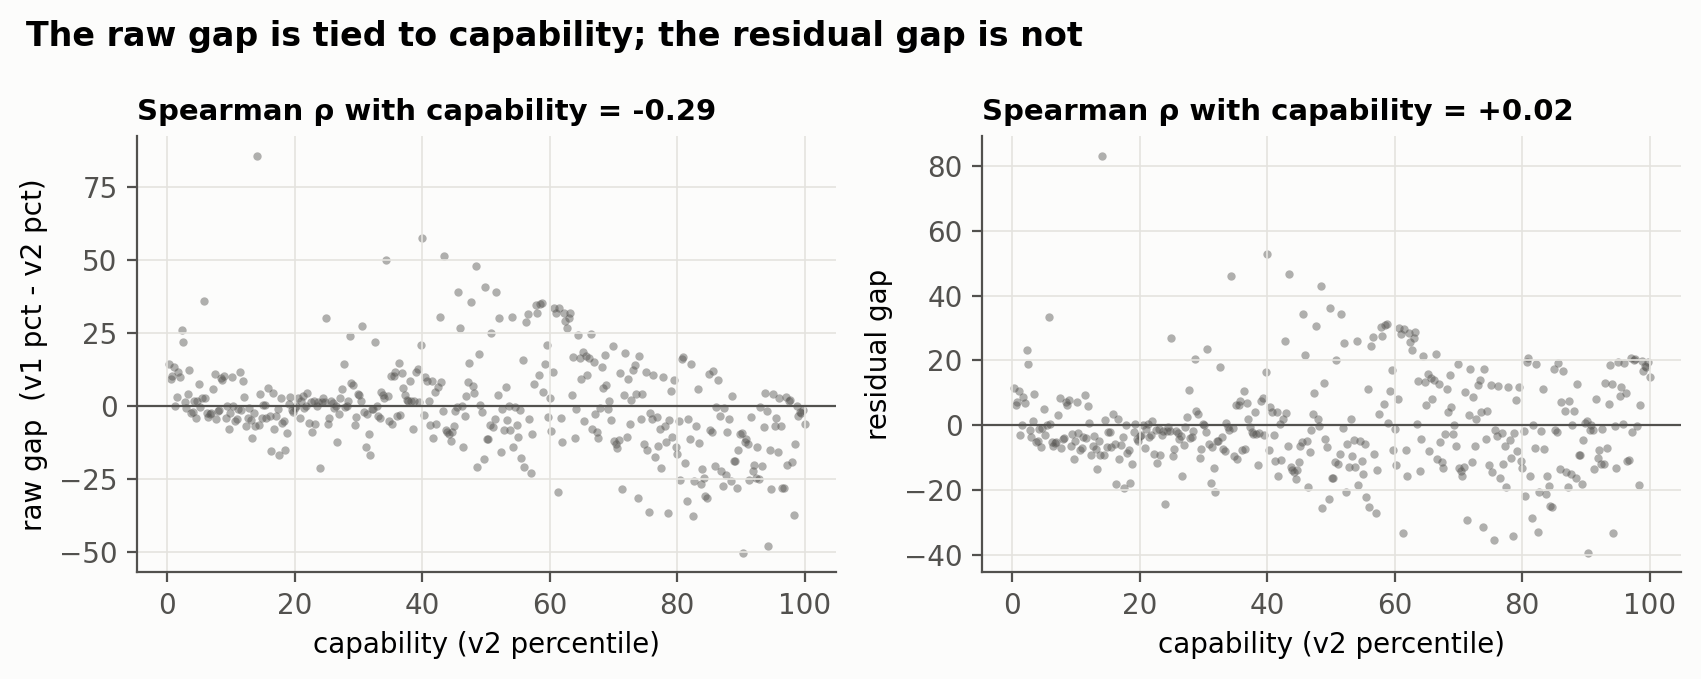

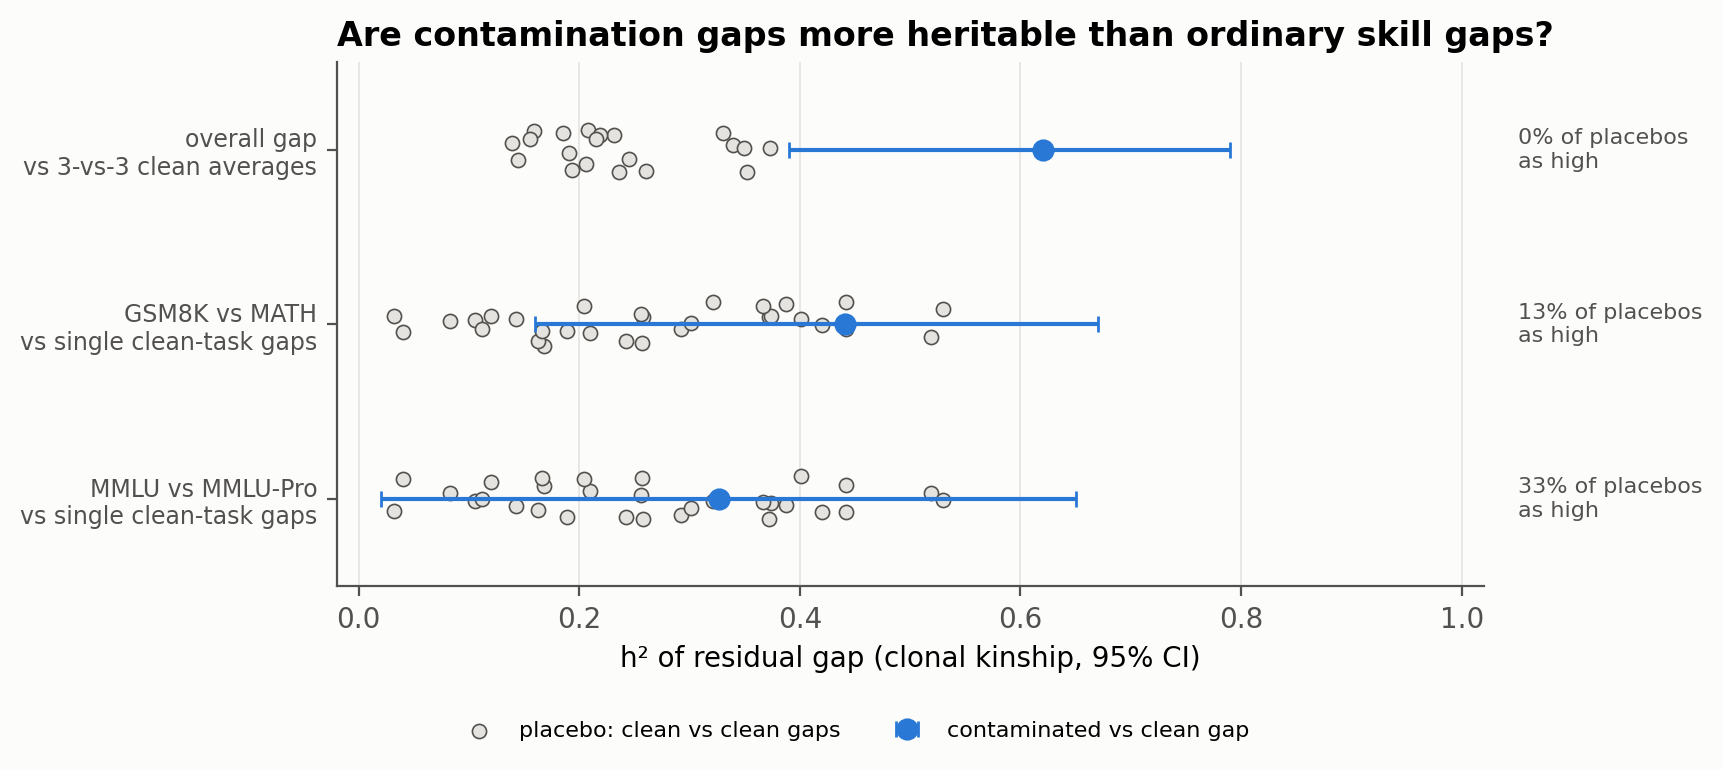

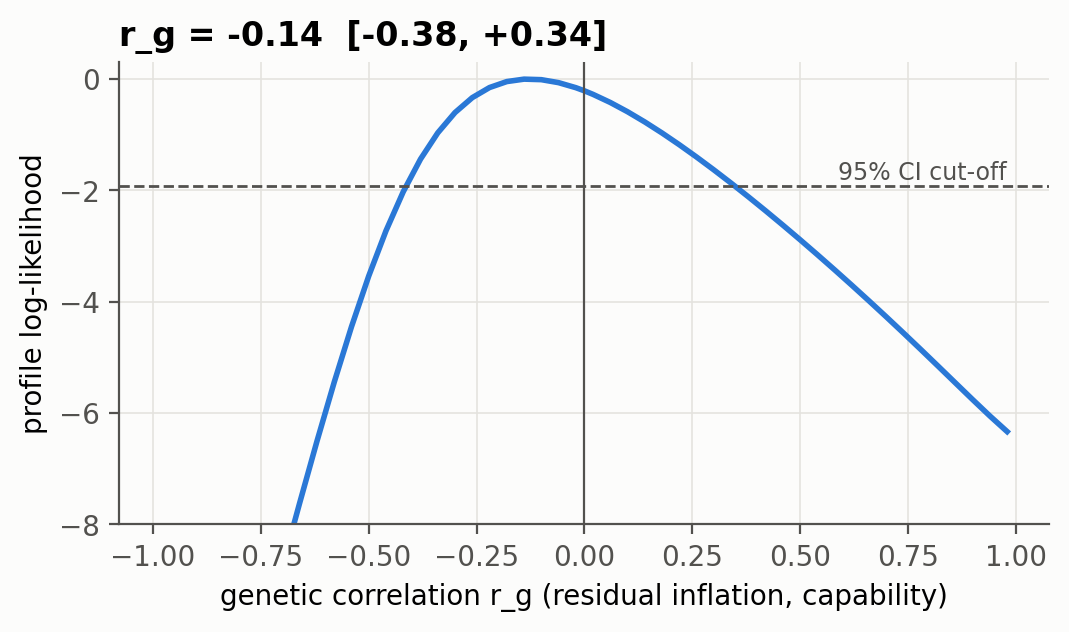

In [7]:
run('phase2_decouple.py', '--data', DATA, '--out', OUT)
show(f'{OUT}/phase2/figs/P2_regression_to_mean.png', f'{OUT}/phase2/figs/P2_placebo.png', f'{OUT}/phase2/figs/P2_rg_profile.png')

## 5. How is it inherited? Merge additivity (Phase 3)
Is a merged model the average of its parents ("additive")? Do merges keep more of their parents' standing on the
contaminated v1 leaderboard than on clean v2, after adjusting for regression to the mean?

[v1] merges n=393: child - mean(parents) = -0.3 pct pts [-1.4,+0.8] p=0.57; within parents 63%, above both 19%; slope 0.91 (p slope=1: 0.0029)
[v1] fine-tunes n=546: child - parent = -1.8 [-3.0,-0.5]
[v2] merges n=467: child - mean(parents) = -4.6 pct pts [-6.4,-2.7] p=1.7e-06; within parents 46%, above both 24%; slope 0.88 (p slope=1: 0.017)
[v2] fine-tunes n=997: child - parent = -0.9 [-1.9,+0.1]
[v1 vs v2 | parent rank, all_merges] v1 bonus minus v2 bonus = +5.6 [+3.3,+8.0] p=3.8e-06  (n v1=393, v2=467)
[v1 vs v2 | parent rank, without_broken_merges] v1 bonus minus v2 bonus = +2.3 [+0.6,+4.0] p=0.0078  (n v1=390, v2=444)
[v1 vs v2] merge bonus v1 -0.3 vs v2 -4.6  (Welch p=0.00012); merges scored on both: 3
leaderboard       task  suspect   n  mean_delta  ci_lo  ci_hi    p
         v1        ARC    False 393       -0.30  -1.29   0.68 0.55
         v1  HellaSwag    False 393       -1.20  -2.28  -0.12 0.03
         v1       MMLU    False 393       -0.31  -1.41   0.79 0.58
         v1 T

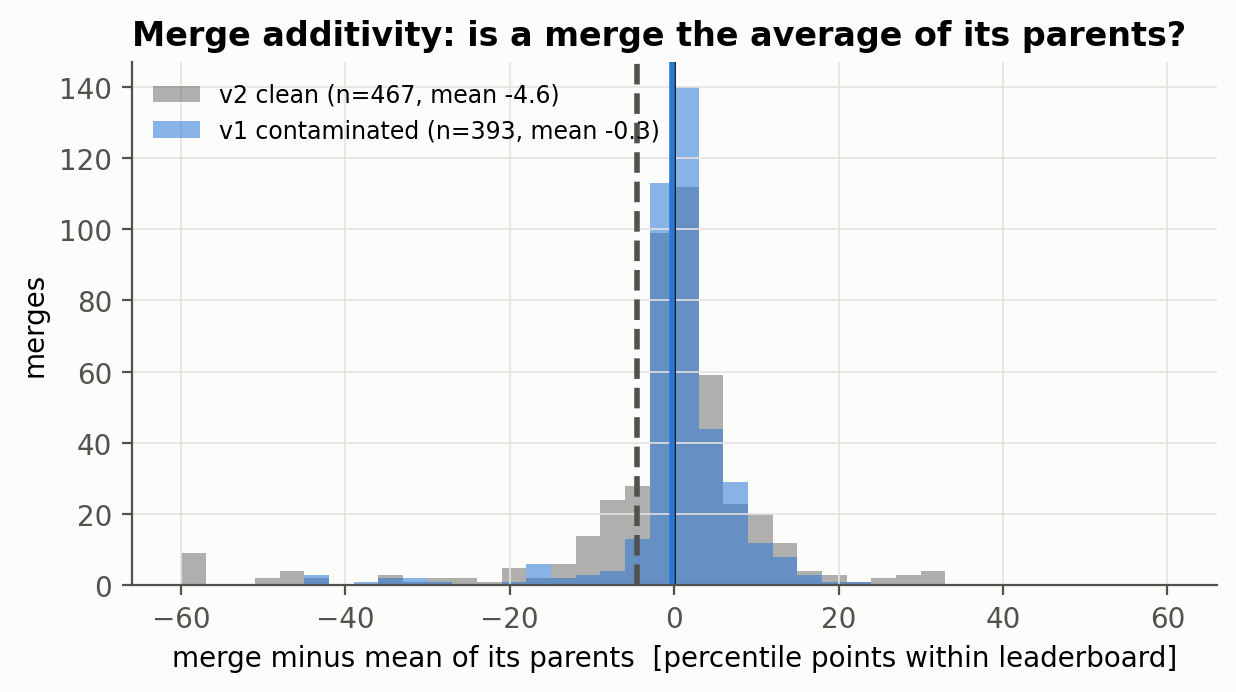

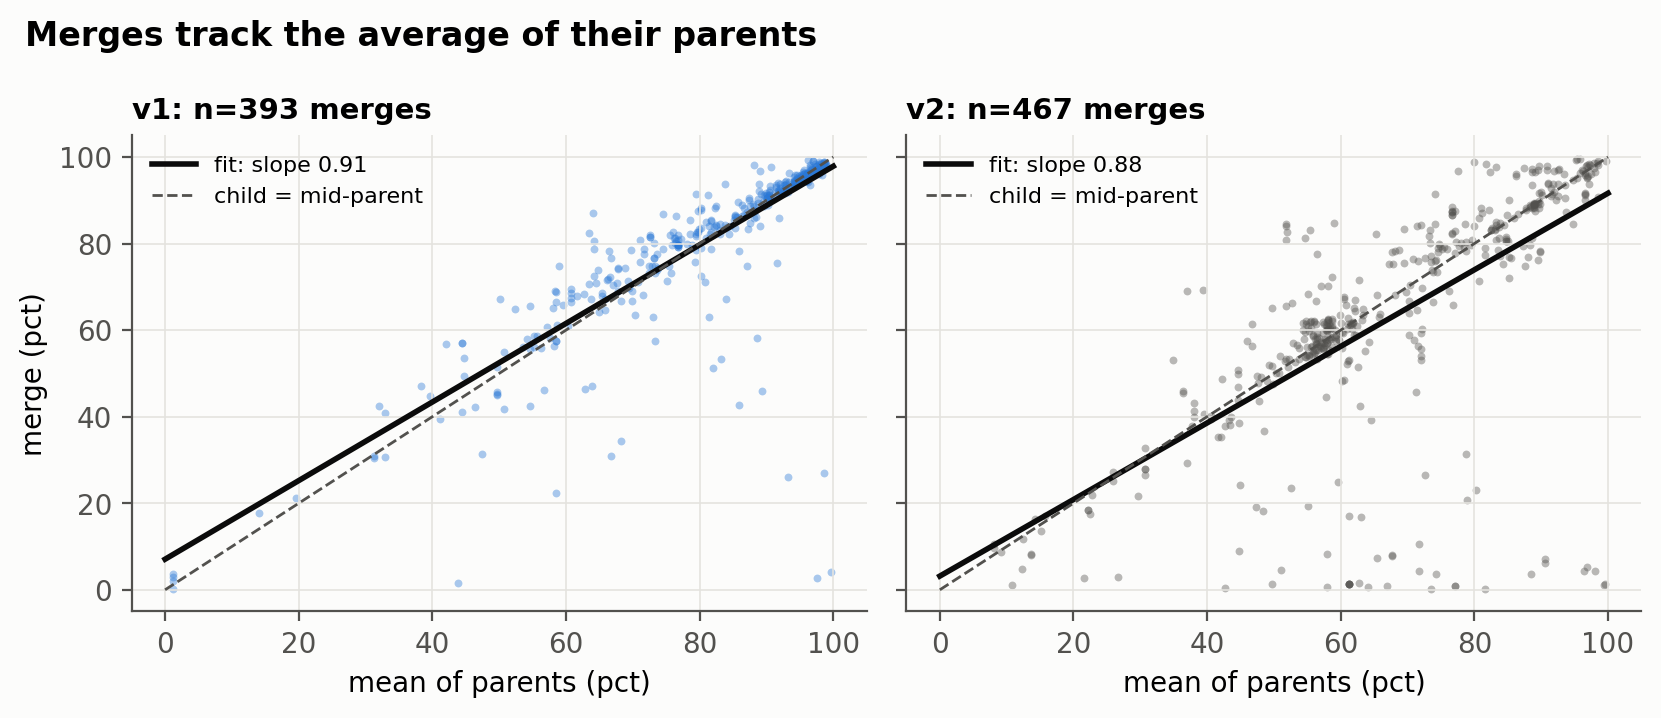

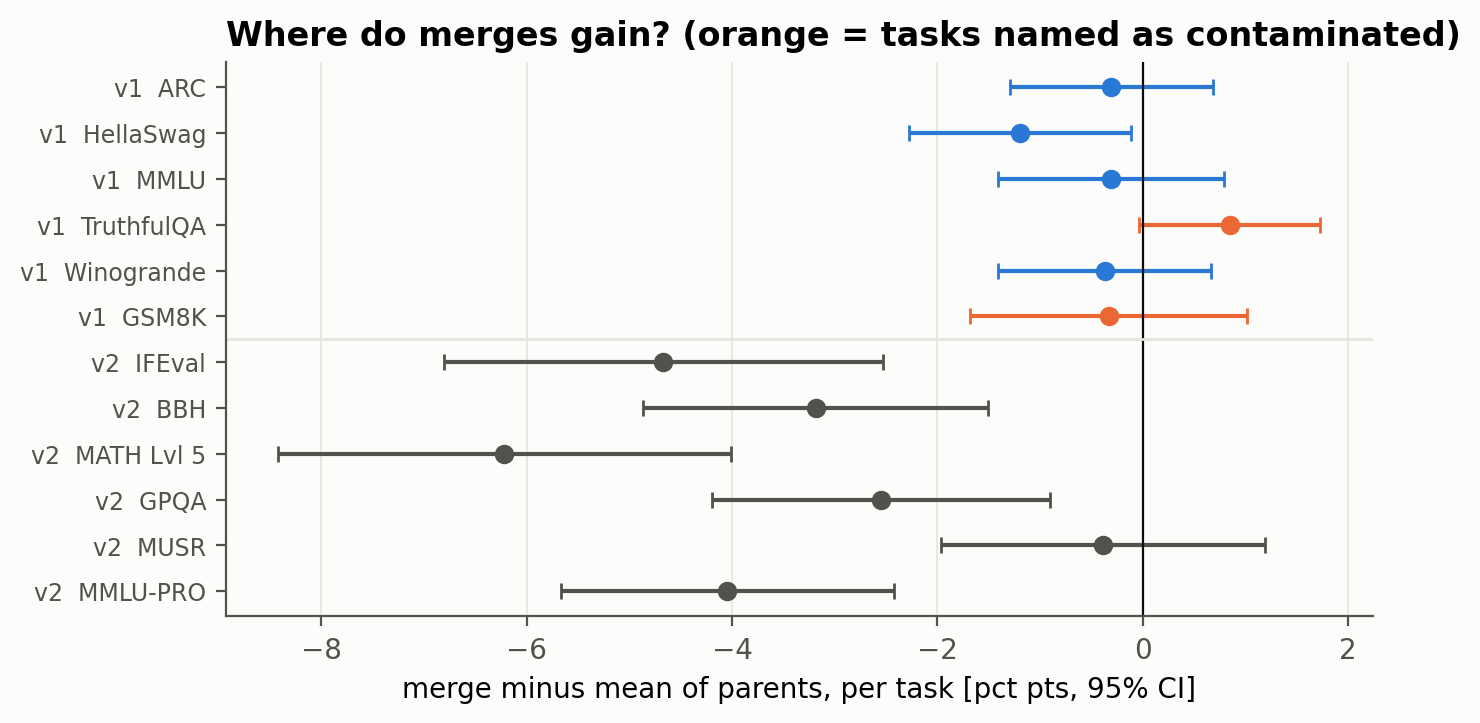

In [8]:
run('phase3_merges.py', '--data', DATA, '--out', OUT)
show(f'{OUT}/phase3/figs/12_merge_additivity.png', f'{OUT}/phase3/figs/P3_midparent.png', f'{OUT}/phase3/figs/P3_task_bonus.png')

## 6. Direct memorisation test (Phase 4: GSM-Symbolic / GSM-Plus)
Each model answers 1,400 paired items: original GSM8K questions vs the same questions with new numbers
(GSM-Symbolic, GSM-Plus numerical substitution) or reworded (GSM-Plus paraphrase), 8-shot chain-of-thought, greedy.
A model that does worse **only when the numbers change** has memorised the originals.
Running the models needs a GPU (`phase4_eval.py`, or `phase4_colab.ipynb` on Colab); the predictions of the pilot run
(5 small models, local RTX 4050) are saved in `out_phase1/phase4/preds`, and the analysis below uses them.

In [9]:
RUN_EVAL = False           # set True on a GPU machine to (re)run the models
if RUN_EVAL:
    run('phase4_eval.py', '--models', f'{OUT}/phase4/models.csv', '--tiers', 'local', '--backend', 'hf', '--out', f'{OUT}/phase4')
run('phase4_analyze.py', '--models', f'{OUT}/phase4/models.csv', '--preds', f'{OUT}/phase4/preds', '--out', f'{OUT}/phase4')
m = pd.read_csv(f'{OUT}/phase4/memorisation_by_model.csv')
m[['model_id', 'n_items', 'acc_orig', 'acc_symbolic', 'acc_numsub', 'acc_paraphrase', 'drop_symbolic', 'drop_symbolic_lo', 'drop_symbolic_hi']].round(3)

                                model_id  acc_orig  acc_symbolic  acc_numsub  drop  infl_math
Josephgflowers/TinyLlama-Cinder-Agent-v1     0.272         0.178       0.207 0.080    -10.247
                       Qwen/Qwen1.5-0.5B     0.195         0.132       0.163 0.052      5.185
                         Qwen/Qwen2-0.5B     0.322         0.238       0.287 0.063      6.667
                         Qwen/Qwen2-1.5B     0.600         0.475       0.500 0.119    -16.667
             stabilityai/stablelm-2-1_6b     0.288         0.176       0.232 0.077     23.457
          proxy          target  n  spearman  p_perm  partial_spearman_given_acc
      infl_math            drop  5    -0.600   0.359                      -0.612
      infl_math        drop_rel  5    -0.200   0.781                      -0.612
      infl_math drop_paraphrase  5     0.205   0.769                       0.154
      inflation            drop  5     0.100   0.945                      -0.105
      inflation        drop_rel

,model_id,n_items,acc_orig,acc_symbolic,acc_numsub,acc_paraphrase,drop_symbolic,drop_symbolic_lo,drop_symbolic_hi
0,Josephgflowers/TinyLlama-Cinder-Agent-v1,1400,0.272,0.178,0.207,0.253,0.092,0.022,0.168
1,Qwen/Qwen1.5-0.5B,1400,0.195,0.132,0.163,0.190,0.078,0.017,0.152
2,Qwen/Qwen2-0.5B,1400,0.322,0.238,0.287,0.333,0.092,0.010,0.180
3,Qwen/Qwen2-1.5B,1400,0.600,0.475,0.500,0.593,0.145,0.070,0.223
4,stabilityai/stablelm-2-1_6b,856,0.288,0.176,0.232,0.252,0.097,-0.013,0.196


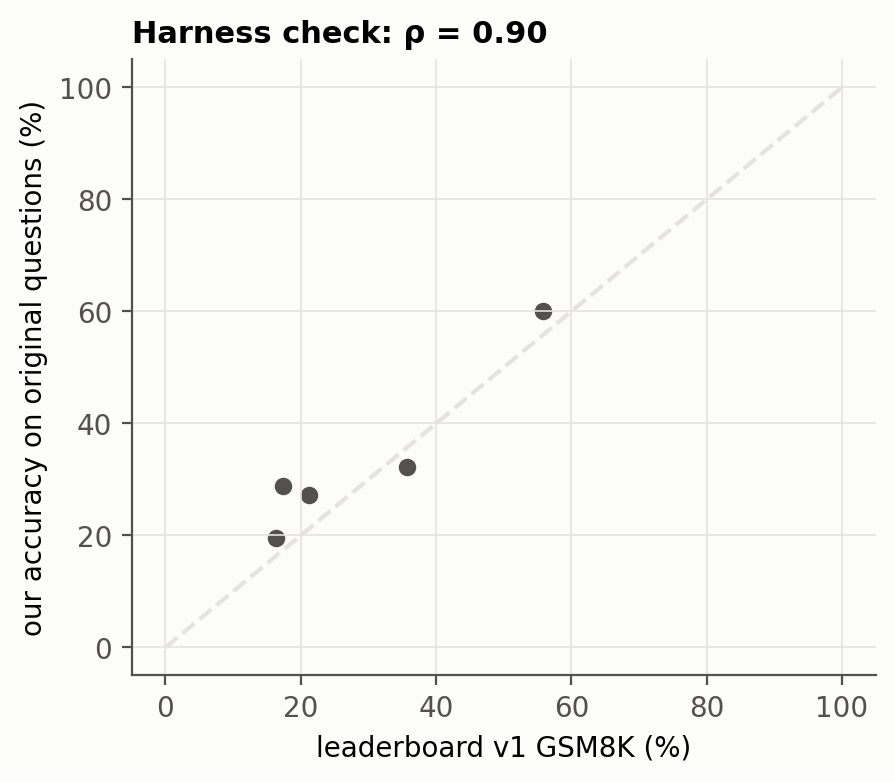

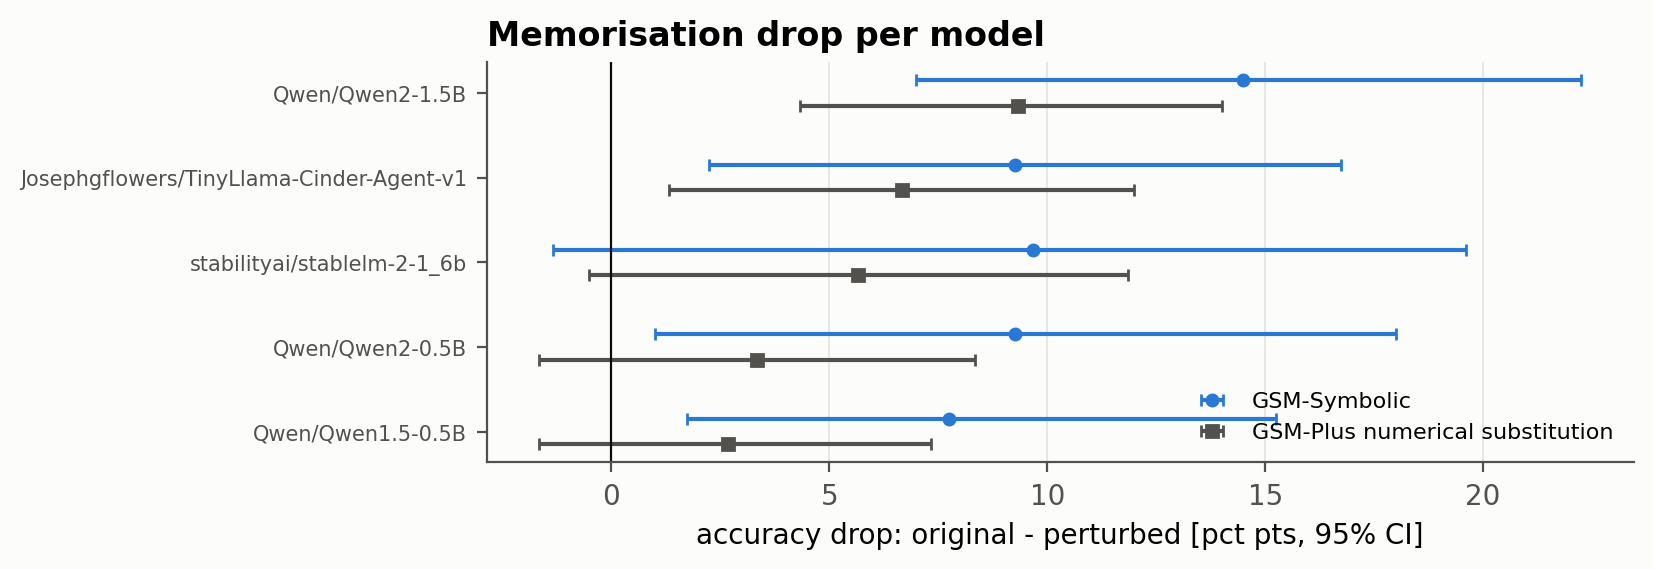

In [10]:
show(f'{OUT}/phase4/figs/P4_harness_check.png', f'{OUT}/phase4/figs/P4_drop_by_model.png')

## 7. Robustness (Phase 5)
hÂ² re-estimated under other kinship, proxy and sample choices, and leaving out each of the 5 largest families.

      "proxy": "residual (cubic)",
      "n": 405,
      "h2": 0.621,
      "ci_lo": 0.39,
      "ci_hi": 0.79,
      "p_lrt": 1.6836172179048132e-08
    },
    {
      "check": "baseline",
      "group": "all",
      "proxy": "residual (linear)",
      "n": 405,
      "h2": 0.58,
      "ci_lo": 0.35,
      "ci_hi": 0.76,
      "p_lrt": 2.599012498475039e-08
    },
    {
      "check": "baseline",
      "group": "all",
      "proxy": "residual (quintic)",
      "n": 405,
      "h2": 0.686,
      "ci_lo": 0.45,
      "ci_hi": 0.84,
      "p_lrt": 1.0213105004595308e-08
    }
  ],
  "raw_h2_range": [
    0.461,
    0.786
  ],
  "residual_h2_range": [
    0.567,
    0.82
  ],
  "n_significant_p05": 24,
  "n_fits": 24
}
[done] phase 5 in out_phase1\phase5/


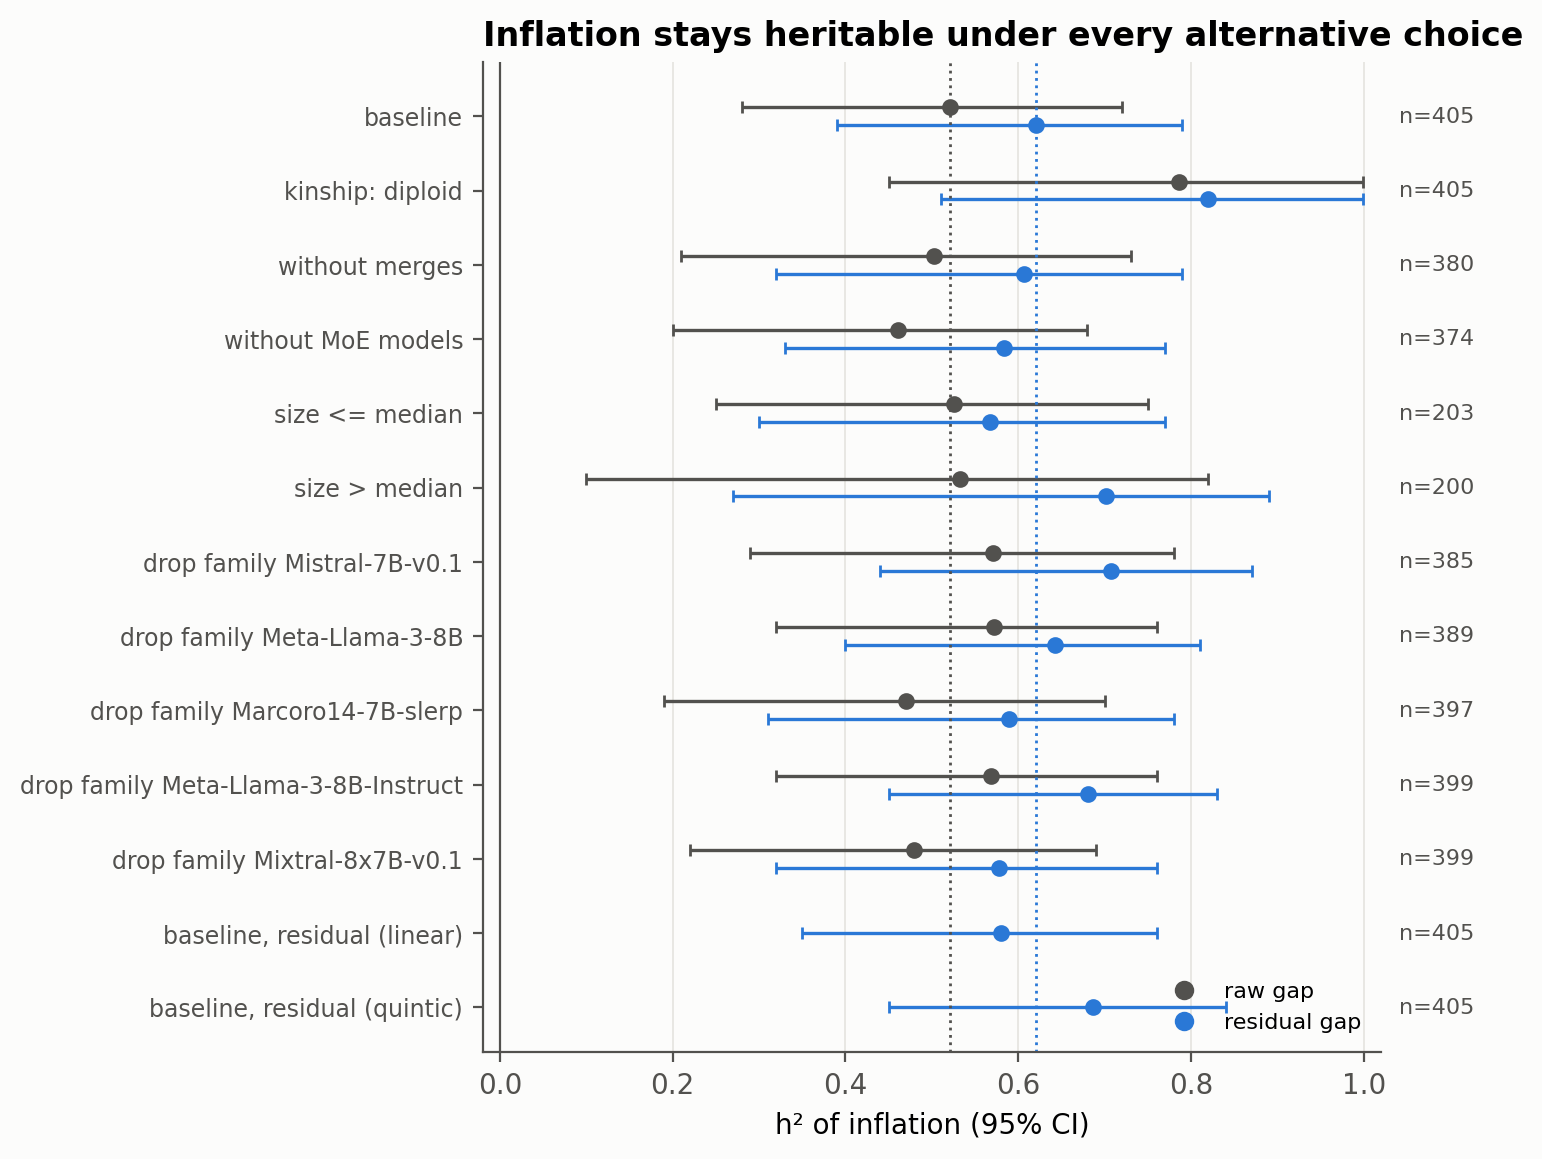

In [11]:
run('phase5_robust.py', '--data', DATA, '--out', OUT)
show(f'{OUT}/phase5/figs/P5_robustness.png')

## 8. Reproducibility check
`make_manifest.py` writes SHA-256 hashes of every result file and the package versions to `out_phase1/MANIFEST.json`.

In [12]:
run('make_manifest.py', '--out', OUT)
man = json.load(open(f'{OUT}/MANIFEST.json'))
print('packages:', man['packages'])

[manifest] 28 entries -> out_phase1/MANIFEST.json
packages: {'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.15.3', 'networkx': '3.4.2', 'matplotlib': '3.10.9', 'huggingface_hub': '0.36.2', 'torch': '2.5.1+cu121', 'transformers': '4.46.3'}


## 9. Summary of findings
| Question | Answer |
|---|---|
| Is the Hub lineage data sufficient? | Yes for the question asked: 13,148 models and 11,541 parent links; 127 of the 405 panel models have a relative in the panel (569 related pairs), and hÂ² is unchanged (0.52) on that subset. |
| Is inflation heritable? | **Yes: hÂ² = 0.52 [0.28, 0.72]** (clonal kinship), LRT p < 10â»â¶, permutation p = 0.015. |
| Is it just inherited capability? | No. The residual proxy is uncorrelated with capability (Ï = 0.02) yet more heritable (hÂ² = 0.62); genetic correlation with capability r_g = âˆ’0.14 [âˆ’0.38, 0.34]; 0 of 20 clean-vs-clean placebo gaps are as heritable. |
| How is it inherited? | Merges are close to additive (child â‰ˆ mean of parents on both leaderboards, slope â‰ˆ 0.9) with a small extra retention on contaminated v1 (+2.3 percentile points, p = 0.008); inflation increases with generation depth. |
| Can lineage alone flag inflated models? | Partly: cross-validated RÂ² 0.23 with the pedigree vs 0.17 with covariates only; detector AUC 0.71. |
| Is it robust? | All 24 robustness fits significant; hÂ² 0.46â€“0.82 across choices; no single family drives it. |
| Direct memorisation evidence? | Pilot: every model tested loses 8â€“15 points when only the numbers change, but only ~1 point when reworded. 5 models are too few to correlate memorisation with the inflation proxy; a 7â€“8B run (47 candidate models) is future work. |

**Limitations.** Lineage metadata is self-reported and incomplete (24% of panel models document parents); the v1â€“v2 gap is
a proxy, not a direct contamination measure; the memorisation validation is a small pilot.